# CSC173 Fine-Tuning a Pretrained CNN
## Group activity notebook: feature extraction, fine-tuning, and a class-wide experiment

In Lecture 03 you used **MobileNetV2** as a frozen feature extractor. Today your group goes one step further and **fine-tunes** it: you unfreeze part of the pretrained network and keep training it, very gently, on a new dataset. Part 3 is a **challenge: the group with the best test accuracy gets a perfect score.** Everything runs on the **TensorFlow Flowers** dataset: 3,670 color photos of 5 kinds of flowers.

By the end of the period your group should be able to:

1. explain **transfer learning**: what is reused, what is trained, and why it works with little data;
2. choose an **optimizer** and a learning rate, and defend the choice;
3. **read training and validation loss curves** and say whether a model underfits, fits well, overfits or diverges;
4. **recognize overfitting** and name two ways to stop it;
5. **interpret a confusion matrix**: which classes get mixed up, and the precision and recall of a class.

| Part | What happens | Clock (60 min) |
|---|---|---|
| 0–1 | Set up, roles, and the data (all code given: just run it) | 0:00–0:07 |
| 2 | Transfer learning: a frozen MobileNetV2, an **optimizer race**, and **overfitting on purpose** | 0:07–0:22 |
| 3 | 🏆 The **fine-tuning challenge**: tune your own recipe | 0:22–0:40 |
| 4 | Your official test score and the **confusion matrix** | 0:40–0:48 |
| 5 | Leaderboard reveal and a **curve-reading gallery** | 0:48–0:60 |

The Experimenter keeps time. If your group falls behind, skip the ✍️ written answers and come back to them while the next model trains: every training cell gives you a minute or two of waiting.

**How to work:** one notebook per group. Fill in every `# TODO`, run the cells from top to bottom, and answer every ✍️ question in the cell below it. There are only **8 TODO cells**, each a few short lines, and each one prints a `Check:` line that should say `True`. Use a GPU: *Runtime → Change runtime type → T4 GPU* **before** class starts the clock. With a GPU every training cell takes 1 to 2 minutes.

---
## 0. Set up

### 0a. Group roles

Pick one role each before you touch the code. Everyone must be able to explain every cell, but each role owns one job.

| Role | Owns | During the activity |
|---|---|---|
| **Driver** | the keyboard | Types the code and runs the cells. Shares the screen so everyone can see. Does **not** decide alone. |
| **Navigator** | the instructions and the Checks | Reads each step aloud, catches bugs, makes sure every `Check:` says `True` before the group moves on. Leads Part 1. |
| **Experimenter** | the challenge strategy | Leads the group's **plan before each trial** in Part 3, watches the clock, and keeps the trial log. |
| **Reporter** | the answers and the share-out | Types the ✍️ answers, posts the group's results line to the leaderboard, and gives the 45-second share-out in Part 5. |

Groups of 3: the Experimenter is also the Reporter. Groups of 5: two Navigators, one of whom keeps a written log of every error and how you fixed it.

In [1]:
GROUP = 20                    # group num is bullshit bc wa pa ta grp num WAHAHA
MEMBERS = {                   # TODO: your names
    "Driver":       "Elia",
    "Navigator":    "Elia",
    "Experimenter": "Kristelle",
    "Reporter":     "Kristelle",
}
print(f"Group {GROUP}:", ", ".join(f"{r} {n}" for r, n in MEMBERS.items() if n))
print("Check:", GROUP > 0 and all(MEMBERS[r] for r in ["Driver", "Navigator", "Experimenter"]))

Group 20: Driver Elia, Navigator Elia, Experimenter Kristelle, Reporter Kristelle
Check: True


### 0b. Libraries and the GPU

In [2]:
import os, time, pathlib, tarfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 173
keras.utils.set_random_seed(SEED)      # same random numbers every run, so results are repeatable
print("TensorFlow", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "none. Use Runtime → Change runtime type → T4 GPU, or training will take about 10 times longer.")

def plot_history(histories, metric="accuracy", title=None, ax=None, boundary=None):
    # Plot training (solid) and validation (dashed) curves for one or more {name: history-dict}.
    ax = ax or plt.gca()
    for (name, h), color in zip(histories.items(), plt.cm.tab10.colors):
        epochs = np.arange(1, len(h[metric]) + 1)
        ax.plot(epochs, h[metric], color=color, label=f"{name} train")
        ax.plot(epochs, h["val_" + metric], "--", color=color, label=f"{name} val")
    if boundary:
        ax.axvline(boundary + 0.5, color="k", ls=":", lw=1)
        ax.text(boundary + 0.6, ax.get_ylim()[0], " fine-tuning starts", fontsize=8, va="bottom")
    ax.set_xlabel("epoch"); ax.set_ylabel(metric); ax.legend(fontsize=8); ax.grid(alpha=.3)
    if title: ax.set_title(title)

TensorFlow 2.21.0
GPU: none. Use Runtime → Change runtime type → T4 GPU, or training will take about 10 times longer.


---
## 1. The data

*Navigator leads Parts 1 and 2.* The dataset is one folder per class. We download it once (about 220 MB, under a minute on Colab).

In [3]:
URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = keras.utils.get_file("flower_photos.tgz", origin=URL)
data_dir = pathlib.Path("flower_photos")
if not data_dir.exists():
    with tarfile.open(archive) as tar:
        tar.extractall(".")

class_names = sorted(d.name for d in data_dir.iterdir() if d.is_dir())
paths, labels = [], []
for c, name in enumerate(class_names):
    files = sorted((data_dir / name).glob("*.jpg"))
    paths += [str(f) for f in files]
    labels += [c] * len(files)
paths, labels = np.array(paths), np.array(labels)
NUM_CLASSES = len(class_names)
print("classes:", class_names)
print("images per class:", np.bincount(labels), " total:", len(paths))

classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
images per class: [633 898 641 699 799]  total: 3670


### 1a. A stratified split

Given code, exactly as in Lecture 04: shuffle each class separately, then give **15% of every class** to validation, **15%** to the test set, and the rest (70%) to training. The test set is locked away until Part 4.

In [4]:
def stratified_split(labels, val_frac=0.15, test_frac=0.15, seed=SEED):
    # Return (train_idx, val_idx, test_idx), each class split in the same proportions.
    rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        rng.shuffle(idx)
        n_val, n_test = int(round(val_frac * len(idx))), int(round(test_frac * len(idx)))
        val_idx.append(idx[:n_val])
        test_idx.append(idx[n_val:n_val + n_test])
        train_idx.append(idx[n_val + n_test:])
    out = [np.concatenate(s) for s in (train_idx, val_idx, test_idx)]
    for s in out:
        rng.shuffle(s)
    return out

tr_idx, va_idx, te_idx = stratified_split(labels)
print("train / val / test sizes:", len(tr_idx), len(va_idx), len(te_idx))
print("val images per class:", np.bincount(labels[va_idx]))
no_overlap = len(set(tr_idx) | set(va_idx) | set(te_idx)) == len(paths)
print("Check:", no_overlap and len(va_idx) == 551 and len(te_idx) == 551)

train / val / test sizes: 2568 551 551
val images per class: [ 95 135  96 105 120]
Check: True


### 1b. Input pipelines

This cell is given. It reads each JPEG, resizes it to **160×160**, and batches 32 images at a time. Pixels stay in 0 to 255 here; the model rescales them itself.

one batch: (32, 160, 160, 3) <dtype: 'float32'>  labels: [4 1 2 0 1 3 4 2 2 1]


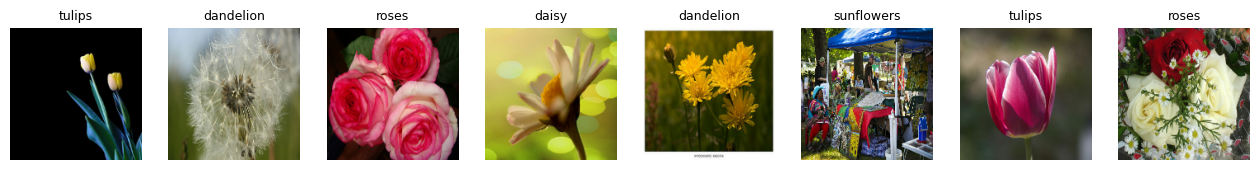

In [5]:
IMG_SIZE = (160, 160)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.uint8), label            # uint8 keeps the cache small

def make_ds(idx, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths[idx], labels[idx]))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(idx), seed=SEED)
    return ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)

train_ds = make_ds(tr_idx, shuffle=True)
val_ds   = make_ds(va_idx)
test_ds  = make_ds(te_idx)

xb, yb = next(iter(train_ds))
print("one batch:", xb.shape, xb.dtype, " labels:", yb[:10].numpy())
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, img, y in zip(axes, xb[:8], yb[:8]):
    ax.imshow(img.numpy().astype("uint8")); ax.set_title(class_names[int(y)], fontsize=9); ax.axis("off")
plt.show()

✍️ **Question 1.** (a) What accuracy would a model get by always predicting the largest class? That is the baseline every result today must beat. (b) Why must the test set stay locked until Part 4, even though we already have a validation set?

*Your answer:*

**(a)** The largest class is **dandelion** (898 out of 3,670 total images; 135 out of 551 in the stratified validation and test sets). Always predicting dandelion gives a baseline accuracy of **898 / 3,670 ≈ 24.47%** (or **135 / 551 ≈ 24.50%** on the validation/test splits, ~**24.5%**).

**(b)** Even though the model does not update its weights directly on the validation set, we repeatedly use validation results in Parts 2 and 3 to choose hyperparameters, architectures, and our best trial. Over multiple trials, those choices indirectly adapt ("overfit") to the validation set, making validation accuracy an optimistically biased estimate of generalization. Keeping the test set untouched until Part 4 preserves an independent, unbiased final evaluation on truly unseen data (and keeps the leaderboard fair).

---
## 2. Stage 1: feature extraction

MobileNetV2 was trained on 1.4 million ImageNet photos. We keep its convolutional **base**, throw away its 1,000-class head, and put a new head for our 5 classes on top.

```
input 160×160×3 → augmentation → rescale to [−1, 1] → MobileNetV2 base (frozen) → global average pool → dropout → Dense(5, softmax)
```

### 2a. Build the model

In [6]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

def build_model(pretrained=True):
    # Return (model, base). pretrained=False gives the same network with random weights.
    base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False,
                                          weights="imagenet" if pretrained else None)
    base.trainable = False                                                # TODO: freeze the whole base (True or False?)
    inputs = keras.Input(IMG_SIZE + (3,))
    x = augment(inputs)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)       # MobileNetV2 expects pixels in [−1, 1]
    # training=False keeps the base's BatchNorm layers in inference mode, even later when we unfreeze them.
    # A network trained from scratch needs its BatchNorm statistics to learn, so it gets training=None.
    x = base(x, training=False if pretrained else None)
    x = layers.GlobalAveragePooling2D()(x)                                # TODO: GlobalAveragePooling2D, turns 5×5×1280 feature maps into a 1280 vector
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)          # TODO: a Dense layer with NUM_CLASSES units and softmax
    return keras.Model(inputs, outputs), base

def count_params(weights):
    return int(sum(np.prod(w.shape) for w in weights))                    # TODO: total number of numbers in a list of weight tensors (np.prod of each shape)

keras.utils.set_random_seed(SEED)
model, base = build_model()
n_train, n_total = count_params(model.trainable_weights), count_params(model.weights)
print(f"base layers: {len(base.layers)} · trainable parameters: {n_train:,} of {n_total:,} ({100 * n_train / n_total:.2f}%)")
print("Check:", n_train == 1280 * NUM_CLASSES + NUM_CLASSES and n_total == model.count_params())

base layers: 154 · trainable parameters: 6,405 of 2,264,389 (0.28%)
Check: True


### 2b. The base as a feature extractor

While the base is frozen it never changes, so we can run every photo through it **once** and keep the 1,280 numbers it produces per photo. Training a head on these saved features takes seconds, which lets us run quick experiments in 2c and 2d. (No augmentation here: each photo gives one fixed feature vector.)

In [7]:
feature_extractor = keras.Sequential([layers.Input(IMG_SIZE + (3,)), layers.Rescaling(1 / 127.5, offset=-1),
                                      base, layers.GlobalAveragePooling2D()])
t0 = time.time()
F_train = feature_extractor.predict(make_ds(tr_idx), verbose=0)
F_val   = feature_extractor.predict(val_ds, verbose=0)
y_tr, y_va = labels[tr_idx], labels[va_idx]
print(f"features: train {F_train.shape}, val {F_val.shape} in {time.time() - t0:.0f} s")

def head_model(hidden=0, dropout=0.0):
    # A head that works on the saved 1,280-number features. hidden > 0 adds two big hidden layers.
    m = keras.Sequential([layers.Input((1280,))])
    for _ in range(2 if hidden else 0):
        m.add(layers.Dense(hidden, activation="relu"))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(NUM_CLASSES, activation="softmax"))
    return m

features: train (2568, 1280), val (551, 1280) in 102 s


### 2c. Which optimizer? A race

Same head, same features, same 15 epochs, the **same learning rate** ($10^{-3}$), four optimizers. Only the optimizer changes.

| Optimizer | Keras | Idea from the lecture |
|---|---|---|
| SGD | `keras.optimizers.SGD(1e-3)` | step straight down the gradient |
| SGD + momentum | `keras.optimizers.SGD(1e-3, momentum=0.9)` | keep a running velocity, so steps build up in a consistent direction |
| RMSprop | `keras.optimizers.RMSprop(1e-3)` | divide each step by a running size of that weight's gradients |
| Adam | `keras.optimizers.Adam(1e-3)` | momentum + RMSprop, with bias correction |

SGD           val loss after 1 epoch 1.335 · after 5 0.749 · after 15 0.504 · lowest 0.504 at epoch 15
SGD+momentum  val loss after 1 epoch 0.568 · after 5 0.365 · after 15 0.311 · lowest 0.311 at epoch 15
RMSprop       val loss after 1 epoch 0.457 · after 5 0.305 · after 15 0.342 · lowest 0.303 at epoch 6
Adam          val loss after 1 epoch 0.467 · after 5 0.312 · after 15 0.313 · lowest 0.301 at epoch 8


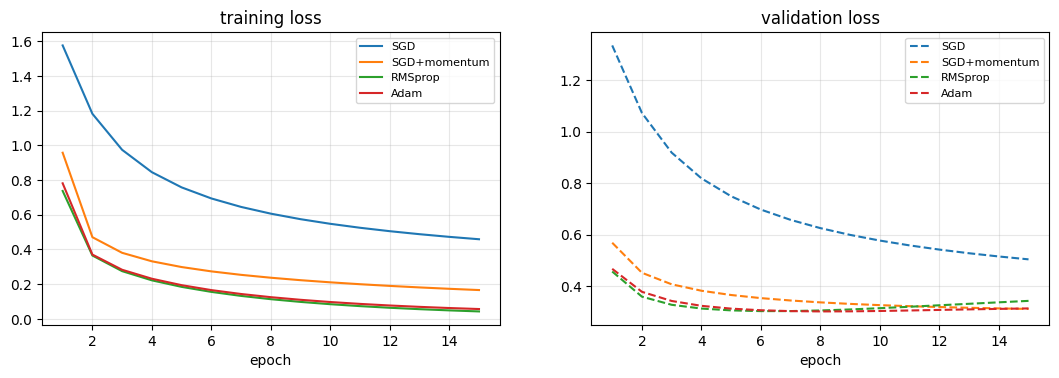

Check: True


In [9]:
def make_optimizers():
    return {
        "SGD":          keras.optimizers.SGD(1e-3),                # TODO
        "SGD+momentum": keras.optimizers.SGD(1e-3, momentum=0.9),  # TODO
        "RMSprop":      keras.optimizers.RMSprop(1e-3),            # TODO
        "Adam":         keras.optimizers.Adam(1e-3),               # TODO
    }

race = {}
for name, opt in make_optimizers().items():
    keras.utils.set_random_seed(SEED)
    m = head_model()
    m.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    race[name] = m.fit(F_train, y_tr, validation_data=(F_val, y_va), epochs=15, batch_size=BATCH, verbose=0).history
    v = race[name]["val_loss"]
    print(f"{name:13s} val loss after 1 epoch {v[0]:.3f} · after 5 {v[4]:.3f} · after 15 {v[-1]:.3f} · lowest {min(v):.3f} at epoch {int(np.argmin(v)) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for (name, h), color in zip(race.items(), plt.cm.tab10.colors):
    axes[0].plot(np.arange(1, 16), h["loss"], color=color, label=name)
    axes[1].plot(np.arange(1, 16), h["val_loss"], "--", color=color, label=name)
for ax, t in zip(axes, ["training loss", "validation loss"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.show()
print("Check:", min(race["Adam"]["val_loss"]) < min(race["SGD"]["val_loss"]))

✍️ **Question 2.** (a) Rank the four optimizers by how fast the validation loss falls. Which would you choose as your default, and why? (b) Plain SGD is the slowest here. Name two things you could change to make it competitive. (c) For the fastest optimizers, the validation loss reaches its lowest point and then creeps back up while the training loss keeps falling. What is that called, and what would you do about it? (d) This head is all that stage 1 of transfer learning trains: 6,405 of 2.26 million parameters. Why does a frozen base trained on ImageNet still give good features for flowers?

*Your answer:*

**(a)** Fastest to slowest (by how quickly validation loss drops):
1. **RMSprop** (0.457 at epoch 1 → 0.305 at epoch 5; lowest 0.303 at epoch 6)
2. **Adam** (0.467 at epoch 1 → 0.312 at epoch 5; lowest 0.301 at epoch 8)
3. **SGD + momentum** (0.568 at epoch 1 → 0.365 at epoch 5; 0.311 at epoch 15)
4. **SGD** (1.335 at epoch 1 → 0.749 at epoch 5; 0.504 at epoch 15)

**Default choice:** **Adam**. It combines momentum with per-parameter adaptive learning rates, converges almost as quickly as RMSprop, achieved the lowest validation loss overall (0.301), and degraded much less than RMSprop in later epochs (0.313 vs. 0.342 at epoch 15), making it a reliable default without much tuning.

**(b)** Two changes to make plain SGD competitive:
1. **Use a larger learning rate** (e.g., `1e-2` instead of `1e-3`, optionally with learning-rate decay), since `1e-3` takes steps that are too small without adaptive scaling.
2. **Add momentum** (e.g., `momentum=0.9`, which immediately closed most of the gap here) — or **train for more epochs**, since plain SGD's validation loss is still falling steadily at epoch 15.

**(c)** That is **overfitting**: the head begins memorizing training-set noise instead of generalizing. To handle it, use **early stopping** (monitoring validation loss with `restore_best_weights=True`) and/or add **regularization** such as **dropout**, **data augmentation**, or weight decay.

**(d)** Because MobileNetV2 was trained on 1.4 million diverse ImageNet images, its convolutional layers already learned general, reusable visual features—edges, colors, textures, curves, and natural shapes/parts. Those representations transfer directly to flower photos, so the small 6,405-parameter head only needs to learn how to combine the 1,280 extracted features to distinguish the 5 flower classes.

### 2d. Overfitting on purpose

Now break it. A **big** head (two hidden layers of 512, about 920,000 parameters) trained on only **10 photos per class** for 150 epochs. Then the same head with **dropout and early stopping**. Watch the two loss curves separate.

big head, no regularization   : epochs run 150 · train acc 1.000 · val loss at the last epoch 1.011 · lowest val loss 0.921 at epoch 5
dropout 0.5 + early stopping  : epochs run  21 · train acc 1.000 · val loss at the last epoch 0.873 · lowest val loss 0.756 at epoch 11


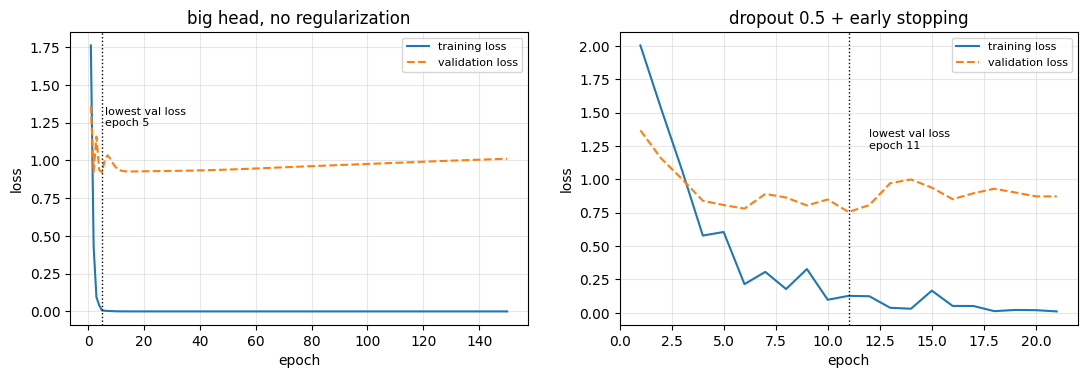

Check: True


In [11]:
rng = np.random.default_rng(SEED)
few = np.concatenate([rng.choice(np.where(y_tr == c)[0], 10, replace=False) for c in range(NUM_CLASSES)])

def fit_head(model, callbacks=None):
    keras.utils.set_random_seed(SEED)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(F_train[few], y_tr[few], validation_data=(F_val, y_va), epochs=150,
                     batch_size=16, callbacks=callbacks or [], verbose=0).history

h_overfit = fit_head(head_model(hidden=512))
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)   # TODO: keras.callbacks.EarlyStopping watching "val_loss", patience 10, restore_best_weights=True
h_regular = fit_head(head_model(hidden=512, dropout=0.5), [early_stop])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (name, h) in zip(axes, [("big head, no regularization", h_overfit), ("dropout 0.5 + early stopping", h_regular)]):
    best = int(np.argmin(h["val_loss"]))
    ax.plot(np.arange(1, len(h["loss"]) + 1), h["loss"], label="training loss")
    ax.plot(np.arange(1, len(h["loss"]) + 1), h["val_loss"], "--", label="validation loss")
    ax.axvline(best + 1, color="k", ls=":", lw=1); ax.text(best + 2, max(h["val_loss"]) * 0.9, f"lowest val loss\nepoch {best + 1}", fontsize=8)
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    print(f"{name:30s}: epochs run {len(h['loss']):3d} · train acc {h['accuracy'][-1]:.3f} · val loss at the last epoch {h['val_loss'][-1]:.3f}"
          f" · lowest val loss {min(h['val_loss']):.3f} at epoch {best + 1}")
plt.show()
print("Check:", isinstance(early_stop, keras.callbacks.EarlyStopping) and len(h_regular["loss"]) < 150)

✍️ **Question 3: reading the curves.** (a) In the left plot, at which epoch does the model start to overfit? Give two signs in the plot that tell you so. (b) Training accuracy is near 100% at the end. Why is that *not* good news? (c) Early stopping keeps the weights from the best epoch. Compare the validation loss of the model you would keep in each plot. Did regularization make 50 photos as good as 2,568? Name one other way to fight overfitting (hint: Part 2e uses it, and the best one is not a layer at all).

*Your answer:*

**(a)** The model starts to overfit right after **epoch 5** (where validation loss hits its minimum of **0.921**). Two signs in the plot:
1. **Validation loss rises while training loss keeps falling:** After epoch 5, the dashed validation loss climbs back up (from 0.921 to 1.011) even as the solid training loss drops almost to 0.
2. **A wide, growing generalization gap:** The training and validation loss curves separate sharply and stay far apart for the rest of training.

**(b)** Reaching ~100% training accuracy with ~920,000 parameters on only 50 training photos just means the model **memorized those 50 examples** (including their noise/background details) instead of learning general flower features. Because validation loss is high and worsening, it generalizes poorly to unseen images.

**(c)** Keeping the best epoch from each plot gives a validation loss of **0.921** (epoch 5, no regularization) vs. **0.756** (epoch 11, dropout 0.5 + early stopping). Regularization helped, **but it did not make 50 photos as good as 2,568** — in Part 2c, Adam on all 2,568 training photos reached a much lower validation loss of **0.301**. Two other ways to fight overfitting are **data augmentation** (random flips, rotations, and zooms, used in Part 2e) and—best of all, and not a layer—**gathering more training data**.

### 2e. Stage 1 on the full model

Back to the full model with augmentation (random flips, rotations and zooms: a regularizer that creates new versions of each photo every epoch). Five epochs with **Adam at $10^{-3}$**, the winner of the race. Only the 6,405 head parameters change. We save the weights so that Part 3 always starts from this exact model, even if you run Part 3 twice.

Epoch 1/5
81/81 - 93s - 1s/step - accuracy: 0.6266 - loss: 0.9853 - val_accuracy: 0.8185 - val_loss: 0.5226
Epoch 2/5
81/81 - 73s - 896ms/step - accuracy: 0.8181 - loss: 0.5037 - val_accuracy: 0.8639 - val_loss: 0.4150
Epoch 3/5
81/81 - 82s - 1s/step - accuracy: 0.8419 - loss: 0.4364 - val_accuracy: 0.8621 - val_loss: 0.3838
Epoch 4/5
81/81 - 76s - 932ms/step - accuracy: 0.8660 - loss: 0.3692 - val_accuracy: 0.8748 - val_loss: 0.3747
Epoch 5/5
81/81 - 83s - 1s/step - accuracy: 0.8777 - loss: 0.3434 - val_accuracy: 0.8820 - val_loss: 0.3470
stage 1 done in 406 s · validation accuracy 0.882


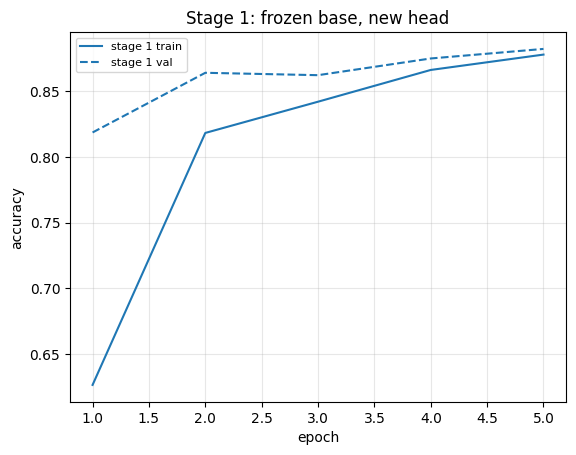

Check: True


In [12]:
WARMUP_EPOCHS = 5
FT_EPOCHS = 5
WARMUP_FILE = "warmup.weights.h5"

def compile_model(model, lr, optimizer="adam"):
    opt = keras.optimizers.Adam(lr) if optimizer == "adam" else keras.optimizers.SGD(lr, momentum=0.9)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

compile_model(model, 1e-3)
t0 = time.time()
warmup = model.fit(train_ds, validation_data=val_ds, epochs=WARMUP_EPOCHS, verbose=2).history
warmup_time = time.time() - t0
model.save_weights(WARMUP_FILE)
warmup_val_acc = warmup["val_accuracy"][-1]
print(f"stage 1 done in {warmup_time:.0f} s · validation accuracy {warmup_val_acc:.3f}")
plot_history({"stage 1": warmup}, "accuracy", "Stage 1: frozen base, new head"); plt.show()
print("Check:", warmup_val_acc > 0.80)

---
## 3. The fine-tuning challenge 🏆

Fine-tuning means: **unfreeze** some of the top layers of the base and keep training them together with the head, usually with a **much smaller learning rate**, so the pretrained features adapt to flowers without being destroyed.

Now it is a competition. **The group with the highest test accuracy gets a perfect score (20/20) for this activity.** Every other group is graded with the rubric.

### 3a. Write the unfreeze function

In [14]:
def set_fine_tune(base, n_unfrozen=None):
    # Make the last n_unfrozen layers of the base trainable and freeze all the others.
    # n_unfrozen=None unfreezes the whole base; n_unfrozen=0 keeps it fully frozen.
    base.trainable = True
    n = len(base.layers) if n_unfrozen is None else n_unfrozen
    for i, layer in enumerate(base.layers):
        layer.trainable = i >= len(base.layers) - n      # TODO: True only for the last n layers (compare i with len(base.layers) - n)

# test it on a throwaway copy
_, test_base = build_model()
set_fine_tune(test_base, 30)
flags = [l.trainable for l in test_base.layers]
print(f"unfrozen layers: {sum(flags)} of {len(flags)} · first unfrozen layer: {test_base.layers[flags.index(True)].name}")
ok_30 = flags == [False] * (len(flags) - 30) + [True] * 30
set_fine_tune(test_base, None); ok_all = all(l.trainable for l in test_base.layers)
set_fine_tune(test_base, 0);    ok_none = not any(l.trainable for l in test_base.layers)
print("Check:", ok_30 and ok_all and ok_none)

unfrozen layers: 30 of 154 · first unfrozen layer: block_13_project_BN
Check: True


### 3b. Challenge rules

*Experimenter leads this part.*

**Your knobs** (a *recipe*):

| Knob | Allowed values | What it controls |
|---|---|---|
| `unfreeze` | `0` to `154`, or `None` for all | how many of the top layers of the base are trained |
| `optimizer` | `"adam"`, `"rmsprop"`, `"sgd"` (SGD with momentum 0.9) | how each gradient becomes a step |
| `lr` | any positive number | the learning rate |
| `epochs` | `1` to `10` | fine-tuning epochs for this trial |
| `early_stopping` | `True` / `False` | stop when the validation loss stops improving (patience 2) and keep the best epoch |

**Fixed for everyone:** the data, the split, the seed, the model, and the stage 1 weights from Part 2e. Every trial starts again from those weights.

1. **Try as many recipes as you have time for** in 3d. Each trial takes about 1 to 2 minutes on a T4 GPU. Most groups fit 3 to 5.
2. **Your entry is chosen for you:** the trial with the highest **validation** accuracy. You never pick by looking at the test set.
3. **The test set is used once**, in Part 4a. The official score cell counts its runs. An entry whose score was computed more than once cannot win (it is still graded normally).
4. **Ties:** every group tied for first (to 3 decimals) gets the perfect score.
5. The instructor may re-run the winning notebook from top to bottom. The test accuracy must come out within 0.02 of the one on the leaderboard (GPUs are not perfectly repeatable).
6. Don't change the given code (split, data, model, `try_recipe`). Changing it disqualifies the entry.

✍️ **Question 4: plan before you run.** Before your first trial, write down your first recipe and one reason for **each** knob, using what you saw in Part 2 (the optimizer race, the overfitting plot) and the lecture. The Experimenter writes it; it is graded on reasoning.

*Your answer:*

### 3c. The trial runner

Given code. `try_recipe` trains one recipe from the stage 1 weights, logs it in `TRIALS`, and keeps the model if it is your best so far on validation. It never touches the test set.

In [ ]:
TRIALS = []                      # one row per trial
ENTRY = {"val_acc": -1}          # your best trial so far, by validation accuracy
ALLOWED_OPT = {"adam", "rmsprop", "sgd"}

def compile_model(model, lr, optimizer="adam"):
    opt = {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop,
           "sgd": lambda lr: keras.optimizers.SGD(lr, momentum=0.9)}[optimizer](lr)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def try_recipe(unfreeze=30, optimizer="adam", lr=1e-5, epochs=5, early_stopping=False, verbose=0):
    assert optimizer in ALLOWED_OPT and 1 <= epochs <= 10 and lr > 0 and (unfreeze is None or 0 <= unfreeze <= 154)
    keras.utils.set_random_seed(SEED)
    model, base = build_model()
    model.load_weights(WARMUP_FILE)                    # every trial starts from stage 1
    set_fine_tune(base, unfreeze)
    compile_model(model, lr, optimizer)                # recompile so the new trainable flags take effect
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)] if early_stopping else []
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=verbose).history
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)    # the weights we actually keep
    history = {k: warmup[k] + h[k] for k in warmup}         # stage 1 + stage 2, for the plots
    row = dict(trial=len(TRIALS) + 1, unfreeze=unfreeze, optimizer=optimizer, lr=lr, epochs_run=len(h["loss"]),
               early_stopping=early_stopping, trainable=count_params(model.trainable_weights),
               val_acc=val_acc, val_loss=val_loss, seconds=time.time() - t0, history=history)
    TRIALS.append(row)
    if val_acc > ENTRY["val_acc"]:
        ENTRY.clear(); ENTRY.update(row, model=model)

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    plot_history({f"trial {row['trial']}": history}, "loss", f"trial {row['trial']}: loss", axes[0], WARMUP_EPOCHS)
    plot_history({f"trial {row['trial']}": history}, "accuracy", "accuracy", axes[1], WARMUP_EPOCHS)
    plt.show()
    show_trials()

def show_trials():
    print(f"{'trial':>5} {'unfreeze':>8} {'optimizer':>9} {'lr':>8} {'epochs':>6} {'early':>5} {'trainable':>10} {'val_acc':>7} {'val_loss':>8} {'time':>6}")
    for r in sorted(TRIALS, key=lambda r: -r["val_acc"]):
        mark = "  ← your entry" if r["trial"] == ENTRY.get("trial") else ""
        print(f"{r['trial']:>5} {str(r['unfreeze']):>8} {r['optimizer']:>9} {r['lr']:>8.0e} {r['epochs_run']:>6} {str(r['early_stopping']):>5} "
              f"{r['trainable']:>10,} {r['val_acc']:>7.3f} {r['val_loss']:>8.3f} {r['seconds']:>5.0f}s{mark}")

### 3d. Your trials

Edit the recipe and run the cell again for each new trial. Watch the curves: if the validation loss jumps up when fine-tuning starts, the learning rate is too big; if nothing moves, it is too small or too few layers are unfrozen; if training loss keeps falling while validation loss rises, you are overfitting.

A safe starting point is `unfreeze=30, optimizer="adam", lr=1e-5, epochs=5`. You can do better.

In [ ]:
try_recipe(unfreeze=..., optimizer=..., lr=..., epochs=..., early_stopping=...)   # TODO: your recipe from Question 4

In [ ]:
# trial 2, 3, ...: copy this line, change one knob at a time, and run
# try_recipe(unfreeze=..., optimizer=..., lr=..., epochs=..., early_stopping=...)

✍️ **Question 5.** (a) Paste your trial table. Which knob changed the validation accuracy the most? (b) For your **worst** trial, read its loss curve: what happened right after fine-tuning started, and why (use the words *learning rate*, *overfitting* or *underfitting*)? (c) Why does the challenge pick your entry by validation accuracy and not by test accuracy?

*Your answer:*

---
## 4. Results

### 4a. The official test score: run this cell ONCE

In [ ]:
TEST_RUNS = globals().get("TEST_RUNS", 0) + 1      # counts how many times this cell has been run
entry_model = ENTRY["model"]
test_loss, test_acc = ...    # TODO: evaluate entry_model on test_ds (verbose=0)
baseline = np.bincount(labels).max() / len(labels)
print(f"OFFICIAL TEST ACCURACY {test_acc:.3f} · entry = trial {ENTRY['trial']} · validation accuracy {ENTRY['val_acc']:.3f}"
      f" · always-the-largest-class baseline {baseline:.3f} · test runs: {TEST_RUNS}")
print("Check:", 0 <= test_acc <= 1 and TEST_RUNS == 1)

### 4b. Where does it go wrong?

The test photos your entry gets wrong with the most confidence.

In [ ]:
probs = entry_model.predict(test_ds, verbose=0)
y_true = labels[te_idx]
y_pred = probs.argmax(1)
wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.1 * len(wrong), 2.8), squeeze=False)
    for ax, i in zip(axes[0], wrong):
        img = load_image(paths[te_idx[i]], 0)[0].numpy()
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} {probs[i].max():.0%}", fontsize=8, color="crimson")
    plt.suptitle("most confident mistakes", fontsize=10); plt.show()

### 4c. The confusion matrix

Row = the true class, column = the predicted class. The diagonal holds the correct answers; every number off the diagonal is a mistake of one particular kind. Build it yourself, then read it.

In [ ]:
def confusion_matrix(y_true, y_pred, k):
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(y_true, y_pred):
        ...                                   # TODO: add 1 to row t, column p
    return cm

cm = confusion_matrix(y_true, y_pred, NUM_CLASSES)
precision = ...   # TODO: diagonal / column sums  (of everything predicted as class c, the fraction that really is c)
recall    = ...   # TODO: diagonal / row sums     (of everything that really is class c, the fraction we found)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap="Blues")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(NUM_CLASSES), class_names, rotation=45); ax.set_yticks(range(NUM_CLASSES), class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Group {GROUP}: test confusion matrix"); plt.show()
for c, name in enumerate(class_names):
    print(f"{name:11s} precision {precision[c]:.3f} · recall {recall[c]:.3f}")
off = cm - np.diag(np.diag(cm))
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"most common mistake: {class_names[i]} predicted as {class_names[j]} ({off[i, j]} photos)")
print("Check:", cm.sum() == len(y_true) and np.trace(cm) == (y_true == y_pred).sum() and np.allclose(recall, [np.mean(y_pred[y_true == c] == c) for c in range(NUM_CLASSES)]))

### 4d. Your leaderboard line

The Reporter copies this line to the **leaderboard**.

In [ ]:
r = ENTRY
result_line = (f"Group {GROUP} | TEST {test_acc:.3f} | val {r['val_acc']:.3f} | unfreeze {r['unfreeze']} | {r['optimizer']} lr {r['lr']:g} | "
               f"{r['epochs_run']} epochs | early stop {r['early_stopping']} | trainable {r['trainable']:,} | trials {len(TRIALS)} | test runs {TEST_RUNS}")
print(result_line)

✍️ **Question 6: reading the confusion matrix.** (a) Is your test accuracy close to your validation accuracy? What would a large gap mean? (b) Which pair of classes is confused most often, and in which direction (true → predicted)? Look at the photos in 4b: is it a reasonable mistake for a person too? (c) Pick the class with the lowest precision and the class with the lowest recall. In one sentence each, say what that number means for a user of the app ("when the app says *rose* ..." / "of all the real roses ...").

*Your answer:*

---
## 5. Leaderboard reveal 🏆

The instructor sorts the leaderboard by test accuracy. The **top 3** Reporters give a **45-second share-out**: your recipe, your best trial, and one thing you learned from a trial that failed. Fill in the top 5 while you listen.

| Rank | Group | Test acc | Val acc | unfreeze | optimizer, lr | epochs | early stop |
|---|---|---|---|---|---|---|---|
| 1 | | | | | | | |
| 2 | | | | | | | |
| 3 | | | | | | | |
| 4 | | | | | | | |
| 5 | | | | | | | |

✍️ **Question 7.** (a) What did the top recipes have in common? Was the gap between first and fifth bigger or smaller than the gap between two groups' validation and test accuracies (i.e. is the winner clearly better, or partly lucky)? (b) A friend has 300 photos of 4 kinds of Philippine mangoes. Using the leaderboard, write their recipe in 3 steps: what to freeze, which optimizer and learning rate, in what order.

*Your answer:*

### 5b. Curve-reading gallery

These six plots are the **training (solid) and validation (dashed) loss** of six reference recipes, shown in a **random order**. The dotted line marks where stage 2 starts (for the run trained from scratch, the line is only a marker: it had no stage 1).

| Recipe | What was done |
|---|---|
| A | stage 1, then top 30 layers, Adam $10^{-5}$ |
| B | stage 1, then all layers, Adam $10^{-5}$ |
| C | stage 1, then all layers, Adam $10^{-3}$ |
| D | stage 1, then top 30 layers, SGD + momentum $10^{-5}$ |
| E | like A, but with only 10 training photos per class |
| F | no pretrained weights, all layers, Adam $10^{-3}$, 10 epochs |

@@GALLERY@@

✍️ **Question 8.** For each run, (a) write one diagnosis: *good fit*, *overfitting*, *underfitting / learning too slowly*, or *a learning rate too big, so the pretrained features were damaged*; (b) say which recipe (A to F) it is; (c) point to the feature of the curve that told you (for example "the validation loss rises after epoch 4 while the training loss keeps falling").

*Your answer:*

### Group contributions

One line per member: your role and one specific thing you did or caught. Groups that list an error and how they fixed it get credit for it.

*Driver:*

*Navigator:*

*Experimenter:*

*Reporter:*

---
## Before you submit

Every `# TODO` is filled in, every `Check:` prints `True`, the notebook has been run from top to bottom (*Runtime → Restart and run all* if you have time; otherwise make sure the outputs match the code), and every ✍️ question is answered. Submit **one notebook per group**, named `Group<N>_FineTuning.ipynb`.